# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [3]:
!git clone https://github.com/Le-Anh-Duy/K4-Track-4-Day10-VisionLanguageModel.git
%cd K4-Track-4-Day10-VisionLanguageModel

Cloning into 'K4-Track-4-Day10-VisionLanguageModel'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 34 (delta 2), reused 34 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 32.21 KiB | 16.11 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/K4-Track-4-Day10-VisionLanguageModel


In [4]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-cf285760-5cd2-b16a-9fe0-19cd5afac033)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 112.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.6 MB/s eta 0:00:00


In [5]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## 1. Dữ liệu: tải và chia split

In [6]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:00<00:00, 205MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [7]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
!python -m pytest -q


...........................s.........................................    [100%]
68 passed, 1 skipped in 0.48s


Tổng số ảnh train: 1422


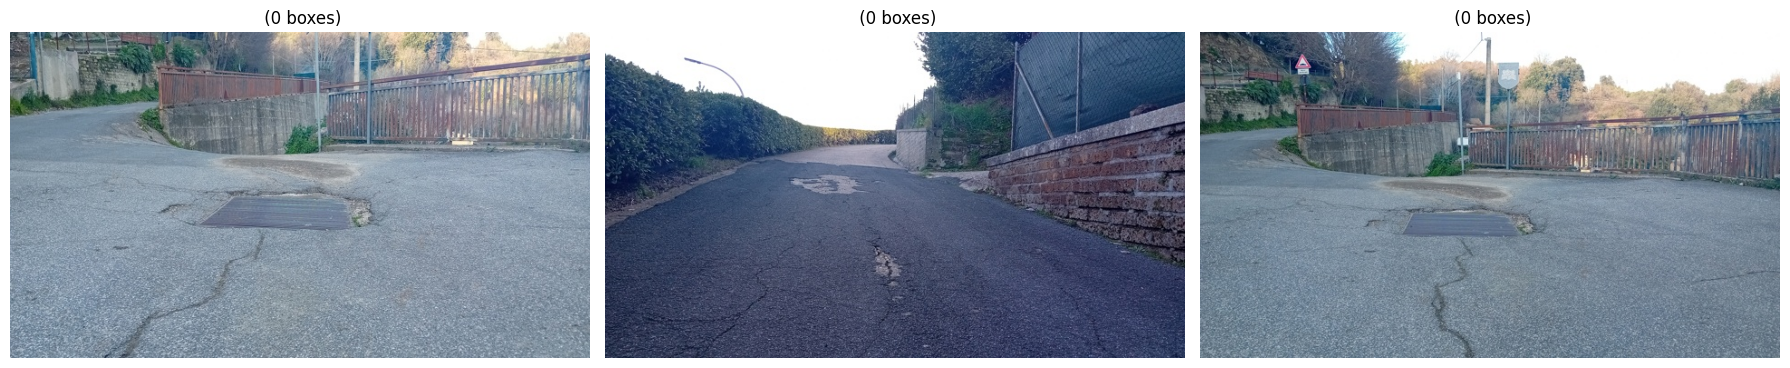

In [11]:
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scripts.labcommon import read_jsonl

# 1. Đọc dữ liệu
train_samples = read_jsonl("data/splits/train.jsonl")
print(f"Tổng số ảnh train: {len(train_samples)}")

COLOR_MAP = {
    "pothole": "red",
    "crack": "yellow",
    "manhole": "cyan"
}

def resolve_image_path(img_path):
    """Tìm đường dẫn ảnh thực tế nếu đường dẫn trong jsonl bị thiếu thư mục cha."""
    candidates = [
        img_path,
        os.path.join("data", img_path),
        os.path.join("data", "images", os.path.basename(img_path)),
        os.path.join("work", "raw", os.path.basename(img_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy ảnh tại các vị trí: {candidates}")

def draw_boxes_on_sample(sample):
    raw_path = sample.get("image") or sample.get("image_path")
    img_path = resolve_image_path(raw_path)

    image = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    boxes = sample.get("boxes", sample.get("annotations", []))

    for item in boxes:
        # Lấy nhãn (chuẩn hóa theo dataset: pothole, crack, manhole)
        label = item.get("category", item.get("label", item.get("name", "unknown")))
        color = COLOR_MAP.get(label, "lime")

        bbox = item.get("bbox", [])
        if len(bbox) == 4:
            xc, yc, w, h = bbox
            # Chuyển đổi tọa độ YOLO chuẩn hóa (0-1) sang pixel (xmin, ymin, xmax, ymax)
            xmin = (xc - w / 2) * width
            ymin = (yc - h / 2) * height
            xmax = (xc + w / 2) * width
            ymax = (yc + h / 2) * height

            # Vẽ bounding box và label
            draw.rectangle([xmin, ymin, xmax, ymax], outline=color, width=3)
            draw.text((xmin + 4, max(0, ymin - 14)), str(label), fill=color)

    return image

# 2. Hiển thị 3 mẫu đầu tiên
samples_to_show = train_samples[:3]
fig, axes = plt.subplots(1, len(samples_to_show), figsize=(18, 6))
if len(samples_to_show) == 1:
    axes = [axes]

for ax, sample in zip(axes, samples_to_show):
    annotated_img = draw_boxes_on_sample(sample)
    img_name = os.path.basename(sample.get("image", ""))
    ax.imshow(annotated_img)
    ax.set_title(f"{sample.get('id', img_name)} ({len(sample.get('boxes', []))} boxes)")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [12]:
import json


def yolo_to_box(label: str, yolo: list[float]) -> dict:
  xc, yc, w, h = yolo  # Chuẩn hoá [0, 1]
  x1 = int(round(max(0.0, min(1000.0, (xc - w / 2) * 1000))))
  y1 = int(round(max(0.0, min(1000.0, (yc - h / 2) * 1000))))
  x2 = int(round(max(0.0, min(1000.0, (xc + w / 2) * 1000))))
  y2 = int(round(max(0.0, min(1000.0, (yc + h / 2) * 1000))))
  if x2 <= x1:
    x2 = min(1000, x1 + 1)
  if y2 <= y1:
    y2 = min(1000, y1 + 1)
  return {"label": label, "bbox_2d": [x1, y1, x2, y2]}


def objects_to_answer(objects: list[dict]) -> str:
  boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
  # Sắp xếp ổn định: trên -> dưới (y1), trái -> phải (x1)
  boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
  return json.dumps(boxes, separators=(",", ":"))


In [13]:
PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d coordinates "
    "normalized on a 0-1000 scale: "
    '[{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. '
    "If no damage is found, output []."
)


## 3. E0: zero-shot

In [14]:
import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["visual", "lm_head"],
)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct",
    quantization_config=quantization,
    device_map="auto",
)
processor = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-4B-Instruct")
processor.tokenizer.padding_side = "left"

# Chạy inference trên tập test và lưu work/e0.jsonl ...


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

In [19]:
import os
import json
import torch
from tqdm import tqdm
from PIL import Image
from scripts.labcommon import read_jsonl

os.makedirs("work", exist_ok=True)
test_samples = read_jsonl("data/splits/test.jsonl")
print(f"Tổng số mẫu test: {len(test_samples)}")

def resolve_image_path(img_path):
    candidates = [
        img_path,
        os.path.join("data", img_path),
        os.path.join("data", "images", os.path.basename(img_path)),
        os.path.join("work", "raw", os.path.basename(img_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy ảnh: {img_path}")

def load_and_resize(path, max_edge=512):
    img = Image.open(path).convert("RGB")
    # Giữ nguyên tỷ lệ, thu nhỏ cạnh dài nhất về max_edge để nén visual token tối đa
    img.thumbnail((max_edge, max_edge), Image.Resampling.BILINEAR)
    return img

BATCH_SIZE = 4
results = []
model.eval()

with torch.inference_mode():
    for i in tqdm(range(0, len(test_samples), BATCH_SIZE), desc="Inference E0 (Batched)"):
        batch_samples = test_samples[i:i + BATCH_SIZE]
        batch_images = [load_and_resize(resolve_image_path(s.get("image") or s.get("image_path"))) for s in batch_samples]

        messages_list = [
            [
                {
                    "role": "user",
                    "content": [
                        {"type": "image", "image": img},
                        {"type": "text", "text": PROMPT},
                    ],
                }
            ]
            for img in batch_images
        ]

        text_prompts = [
            processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
            for m in messages_list
        ]

        inputs = processor(
            text=text_prompts,
            images=batch_images,
            padding=True,
            return_tensors="pt"
        ).to(model.device)

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False
        )

        # Cắt bỏ phần prompt tokens theo từng mẫu
        in_len = inputs.input_ids.shape[1]
        generated_ids_trimmed = generated_ids[:, in_len:]

        batch_outputs = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )

        for s, pred_text in zip(batch_samples, batch_outputs):
            res_item = dict(s)
            res_item["prediction"] = pred_text.strip()
            results.append(res_item)

# Lưu kết quả
with open("work/e0.jsonl", "w", encoding="utf-8") as f:
    for item in results:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Đã lưu xong {len(results)} kết quả vào work/e0.jsonl")

Tổng số mẫu test: 311


Inference E0 (Batched): 100%|██████████| 78/78 [39:15<00:00, 30.20s/it]

Đã lưu xong 311 kết quả vào work/e0.jsonl


In [22]:
from scripts.labcommon import read_jsonl
import json

data = read_jsonl("work/e0.jsonl")

fixed_data = []
for row in data:
    item = dict(row)
    # Gán image_id nếu chưa có
    if "image_id" not in item:
        item["image_id"] = item.get("id") or item.get("image", "")
    # Gán raw từ prediction
    if "raw" not in item:
        item["raw"] = item.get("prediction", "")
    fixed_data.append(item)

with open("work/e0.jsonl", "w", encoding="utf-8") as f:
    for item in fixed_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Đã cập nhật xong {len(fixed_data)} mẫu trong work/e0.jsonl với trường 'raw' và 'image_id'!")

Đã cập nhật xong 311 mẫu trong work/e0.jsonl với trường 'raw' và 'image_id'!


In [23]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.868 P=0.064 R=0.031 F1=0.042 CI95=0.025-0.060 meanIoU=0.607 FP/img=0.85
   pothole  P=0.269 R=0.058 F1=0.095
   crack    P=0.010 R=0.007 F1=0.008
   manhole  P=0.150 R=0.055 F1=0.081


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
# YOUR CODE HERE: encode_example() và collate() (GUIDE bước 4)

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
# YOUR CODE HERE: apply_setup(model, setup) (GUIDE bước 5)

## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9